# 02 · PD scorecard, challenger model and underwriting cut-off

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/climate-tech-energy-finance/solar-loan-credit-risk/notebooks/02_pd_scorecard_and_underwriting.ipynb)

Goal: a 12-month probability of default (PD) that an underwriter can defend line by line, and a score cut-off that keeps the approved book under a 2% bad rate.

* Target: default (90+ days past due) within 12 months of origination. Loans younger than 12 months are left out, so a loan that hasn't had time to default never counts as "good".
* Split: out of time. Loans from Jan 2023 to Jun 2024 train the model; Jul 2024 to Oct 2025 test it.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "climate-tech-energy-finance/solar-loan-credit-risk"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "solar_credit").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: solar-loan-credit-risk


In [2]:
from solar_credit.data_generator import load_loan_book
from solar_credit.features import build_model_data
from solar_credit.scorecard import Scorecard
from solar_credit.models import GradientBoostingPD, evaluate, calibration_table, binomial_test_by_grade
from solar_credit.underwriting import DecisionEngine, strategy_table, choose_cutoff
from solar_credit import reporting

book = load_loan_book()
md = build_model_data(book.loans)
print(f"train: {len(md.train):,} loans, {md.y_train.sum()} defaults ({md.y_train.mean():.2%})")
print(f"test:  {len(md.test):,} loans, {md.y_test.sum()} defaults ({md.y_test.mean():.2%})")

train: 3,692 loans, 105 defaults (2.84%)
test:  5,464 loans, 164 defaults (3.00%)


## Feature screening with information value

Bureau score is the strongest single driver. Second is the savings coverage ratio: the customer's expected monthly energy savings divided by the loan instalment. When the panels pay most of the instalment, the loan rarely goes bad. Regional unemployment and income fall below the 0.02 IV threshold and are dropped.

In [3]:
sc = Scorecard().fit(md.X_train, md.y_train)
sc.iv_table()

,feature,information_value,selected
0,bureau_score,1.217431,True
1,savings_coverage_ratio,0.514902,True
2,product_type,0.233248,True
3,employment_type,0.153959,True
4,dti_ratio,0.091225,True
5,installer_tenure_years,0.086704,True
6,term_months,0.069772,True
7,loan_amount_eur,0.036411,True
8,net_monthly_income_eur,0.018486,False
9,region_unemployment_pct,0.005045,False


In [4]:
pts = sc.points_table()
pts.loc[pts["feature"].isin(["bureau_score", "savings_coverage_ratio"]), ["feature", "bin", "n", "bad_rate", "woe", "points"]]

,feature,bin,n,bad_rate,woe,points
0,bureau_score,"(-inf, 666.0]",745,0.088591,-1.184122,40
1,bureau_score,"(666.0, 730.0]",736,0.023098,0.208078,80
2,bureau_score,"(730.0, 785.0]",738,0.020325,0.334983,83
3,bureau_score,"(785.0, 851.0]",748,0.008021,1.229943,108
4,bureau_score,"(851.0, inf]",725,0.001379,2.671739,149
10,savings_coverage_ratio,"(-inf, 0.431]",740,0.056757,-0.708846,57
11,savings_coverage_ratio,"(0.431, 0.829]",738,0.036585,-0.255088,68
12,savings_coverage_ratio,"(0.829, 1.027]",741,0.032389,-0.131178,71
13,savings_coverage_ratio,"(1.027, 1.187]",736,0.009511,1.069179,99
14,savings_coverage_ratio,"(1.187, inf]",737,0.006784,1.383438,107


## Champion vs challenger

The gradient-boosting challenger fits the training years far better (its train AUC is near 0.97) but loses on the later test vintages. The scorecard wins on AUC, KS and calibration, and it explains itself, so it stays the champion.

In [5]:
gbm = GradientBoostingPD().fit(md.X_train, md.y_train)
pd_sc, pd_gb = sc.predict_pd(md.X_test), gbm.predict_pd(md.X_test)
pd.DataFrame([
    evaluate(md.y_test, pd_sc, "Scorecard (test)"),
    evaluate(md.y_test, pd_gb, "Gradient boosting (test)"),
    evaluate(md.y_train, gbm.predict_pd(md.X_train), "Gradient boosting (train)"),
])

,model,auc,gini,ks,brier,predicted_dr,observed_dr
0,Scorecard (test),0.8189,0.6379,0.5474,0.02778,0.0283,0.0300
1,Gradient boosting (test),0.8082,0.6164,0.5081,0.02781,0.0273,0.0300
2,Gradient boosting (train),0.9691,0.9382,0.8340,0.01926,0.0285,0.0284


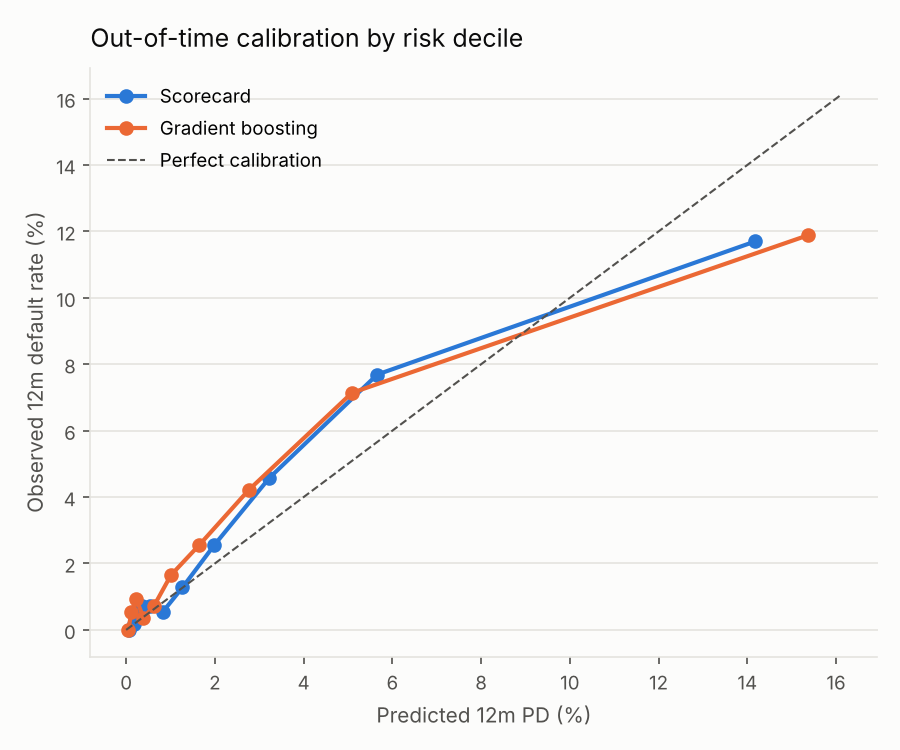

,grade,loans,defaults,predicted_pd,observed_dr,z,p_value,flag
0,1,1093,106,0.0993,0.0970,-0.2543,0.6004,OK
1,2,1093,39,0.0261,0.0357,1.9907,0.0233,Underestimated
2,3,1092,10,0.0105,0.0092,-0.4215,0.6633,OK
3,4,1093,8,0.0044,0.0073,1.4486,0.0737,OK
4,5,1093,1,0.0012,0.0009,-0.2865,0.6127,OK


In [6]:
calib = {"Scorecard": calibration_table(md.y_test, pd_sc), "Gradient boosting": calibration_table(md.y_test, pd_gb)}
display(Image(filename=str(reporting.plot_calibration(calib, Path("outputs/figures/calibration.png")))))
binomial_test_by_grade(md.y_test, pd_sc)

One of five grades shows more defaults than predicted at the 5% level. With five tests one false alarm is not unusual, but in production it would go on the watch list for the next quarterly review.

## Choosing the cut-off

Each point is a score cut-off. Moving from 560 to 580 gives up about 10 points of approval rate and cuts the approved bad rate from 2.0% to 1.3%. The engine picks the lowest cut-off that stays under 2%.

Chosen cut-off: 580


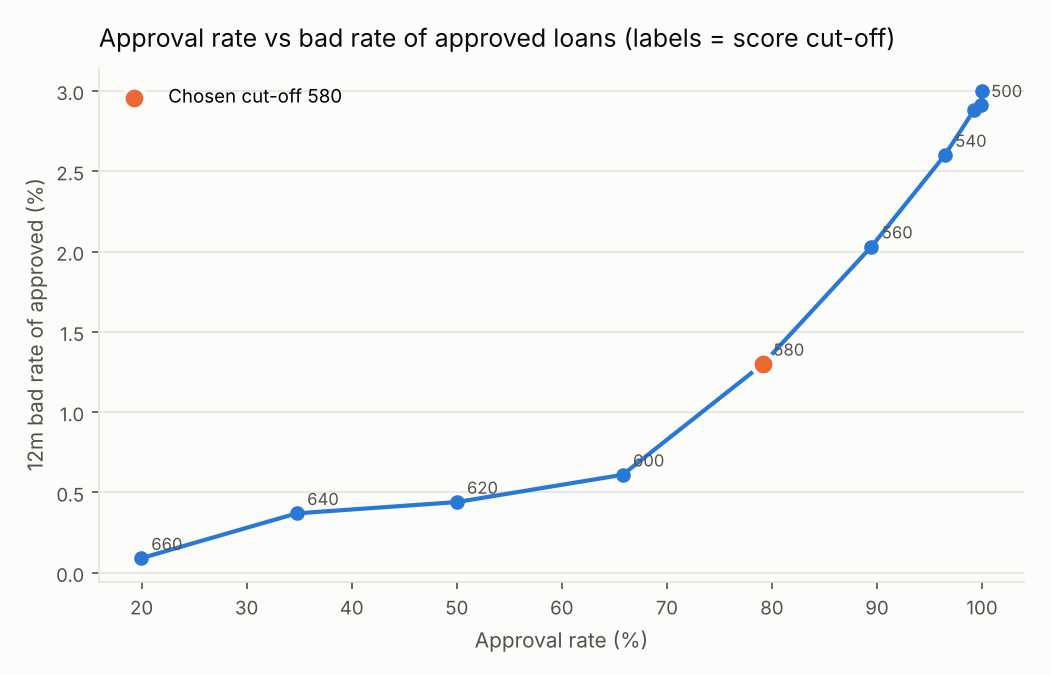

,cutoff,approval_rate,approved_bad_rate,declined_bad_rate,bads_avoided_share
0,480,1.0000,0.0300,NaN,0.0000
1,500,0.9987,0.0291,0.7143,0.0305
2,520,0.9923,0.0288,0.1905,0.0488
3,540,0.9645,0.0260,0.1392,0.1646
4,560,0.8946,0.0203,0.1128,0.3963
5,580,0.7914,0.0130,0.0947,0.6585
6,600,0.6578,0.0061,0.0759,0.8659
7,620,0.4998,0.0044,0.0556,0.9268
8,640,0.3477,0.0037,0.0441,0.9573
9,660,0.1993,0.0009,0.0373,0.9939


In [7]:
strategy = strategy_table(md.y_test, sc.score(md.X_test))
cutoff = choose_cutoff(strategy, max_bad_rate=0.02)
print("Chosen cut-off:", cutoff)
display(Image(filename=str(reporting.plot_strategy(strategy, cutoff, Path("outputs/figures/cutoff_strategy.png")))))
strategy

## Decisions with reason codes

Policy rules run first: debt-to-income above 45%, bureau score under 400, or PV savings covering less than 35% of the instalment are declines whatever the score. Below the cut-off there is a 20-point refer band for manual review. Every decline lists where the applicant lost the most points.

In [8]:
engine = DecisionEngine(sc, cutoff)
decisions = DecisionEngine.to_frame(engine.decide(md.test.sample(12, random_state=3)))
decisions

,application_id,decision,score,pd_12m,reasons
0,LN-004016,Approve,608,0.0153,
1,LN-001875,Approve,636,0.0061,
2,LN-000656,Decline,552,0.0995,Score 552 below cut-off 580; bureau_score (-10...
3,LN-004899,Approve,632,0.0067,
4,LN-004668,Refer,569,0.0567,Score 569 in refer band; bureau_score (-109 pt...
5,LN-001845,Decline,528,0.1975,Score 528 below cut-off 580; bureau_score (-10...
6,LN-002723,Approve,637,0.0057,
7,LN-006177,Decline,585,0.0306,Policy: DTI 58% above 45%
8,LN-002443,Approve,660,0.0025,
9,LN-004168,Approve,629,0.0072,


In [9]:
DecisionEngine.to_frame(engine.decide(md.test))["decision"].value_counts(normalize=True).round(3)

decision
Approve    0.776
Decline    0.124
Refer      0.100
Name: proportion, dtype: float64